# Simulation of the Convolution of Neutron spectrum and Chopper opening function
Create increasingly difficult neutron spectra  
Create increasingly difficult chopper functions  
Convolute the functions  
Compare the outputs of the convoluted functions to the output of approximations

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

import scipy as scp

from tof_helper_functions.tof_framework import RawTOFPointList, RebinnedTOFPointList
from tof_helper_functions.tof_simulation_objects import Chopper, Detector
#plt.style.use('stylesheet.mplstyle')

In [2]:
def poissonian(A, k, lam): # optimized for large values of k and lam
    ln_a = k* np.log(lam)
    ln_b = -lam
    ln_c = np.log(scp.special.factorial(k))
    if isinstance(k,np.ndarray):
        if len(k)>500: # Stirling approximation to 4th order for large k
            ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
    return  A * np.exp(ln_a + ln_b - ln_c)

In [3]:
# generate poissonian spectrum N(bin)
n = 4000
n_max =  n-1
A = 200000
lam =   800
sigma = 20

k_list = np.linspace(0,n_max,n)

# this gaussian noise is not used for the signal
# estimate signal as pure
# noise is from detector
np.random.seed(0) # for reproducibility
gaussian_error_list = [np.random.normal(0,sigma) for i in k_list]
for a in range(len(gaussian_error_list)):
    if gaussian_error_list[a]<0:
        gaussian_error_list[a]=0
poisson_signal_list = poissonian(A, k_list, lam=lam)
signal_with_noise_list = poisson_signal_list+gaussian_error_list

C:\Users\fisch\AppData\Local\Temp\ipykernel_28268\3666959843.py:7: RuntimeWarning: divide by zero encountered in log
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
C:\Users\fisch\AppData\Local\Temp\ipykernel_28268\3666959843.py:7: RuntimeWarning: invalid value encountered in multiply
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
C:\Users\fisch\AppData\Local\Temp\ipykernel_28268\3666959843.py:7: RuntimeWarning: divide by zero encountered in divide
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)


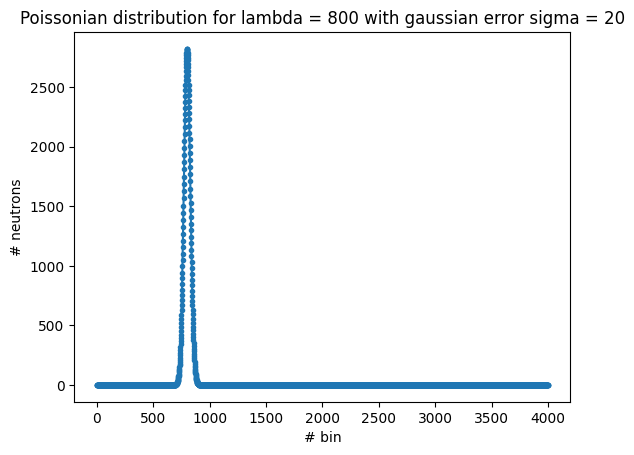

Text(0.5, 1.0, 'Incoming neutron spectrum')

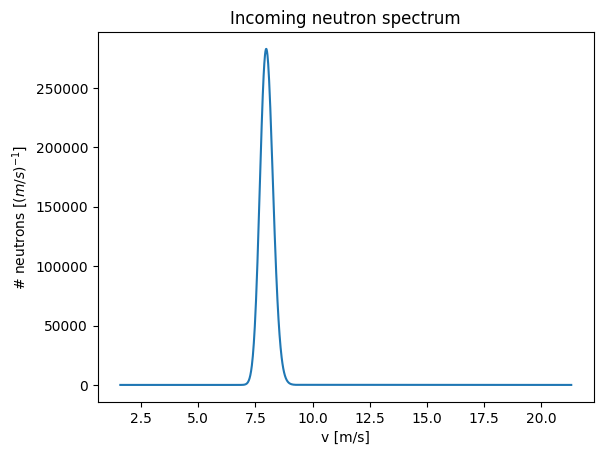

In [4]:
# feed the poissonian signal into the TOF framework
rawTOF_poissonian = RawTOFPointList(poisson_signal_list, 
                         s=631, 
                         label = "Poissonian")
v_max = 15.0
v_min = 3.5
v_step = 0.05
rebinnedTOF_poissonian = RebinnedTOFPointList(rawTOF_poissonian,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned Poissonian")


plt.plot(rawTOF_poissonian.bin_number, rawTOF_poissonian.N_bin, marker='.') 
plt.xlabel("# bin")
plt.ylabel("# neutrons")
plt.title(f"Poissonian distribution for lambda = {lam} with gaussian error sigma = {sigma}")
#plt.legend()
plt.show()

plt.clf()
plt.plot(rawTOF_poissonian.v[300:None], rawTOF_poissonian.N_v[300:None])
plt.xlabel("v [m/s]")
plt.ylabel(r"# neutrons [$(m/s)^{-1}$]")
plt.title("Incoming neutron spectrum")

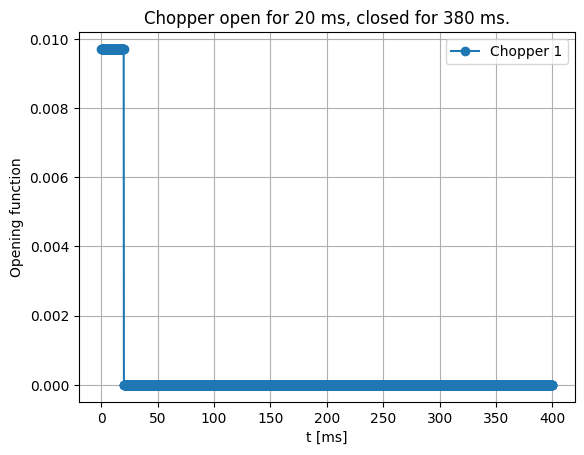

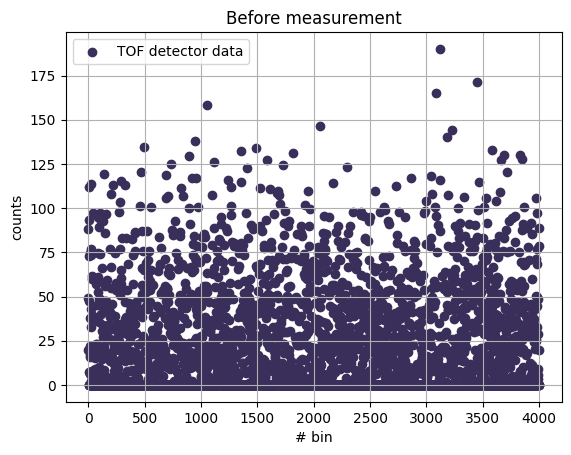

In [5]:
# chopper cycle open for 20 m and close for 380 ms
chopper_cycle_time_ms = 400
chopper_open_time_ms = 20
chopper1 = Chopper("Chopper 1", num_chop=2057, t_open_ms=chopper_open_time_ms, t_close_ms=chopper_cycle_time_ms-chopper_open_time_ms)
chopper1.renormalize_opening_function()
chopper1.plot()

# detector
detector1 = Detector(num_bins=4000, 
                     s_mm=639, 
                     do_cycle=False,
                     do_gaussian_noise=True,
                     sigma = 50)
detector1.plot(title="Before measurement")
detector1.measure(rawTOF_poissonian, chopper1)


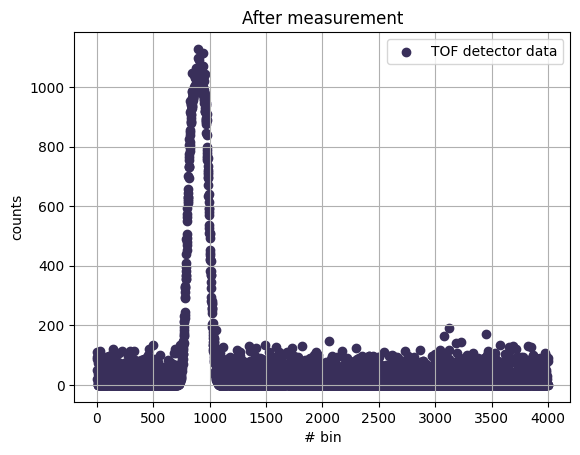

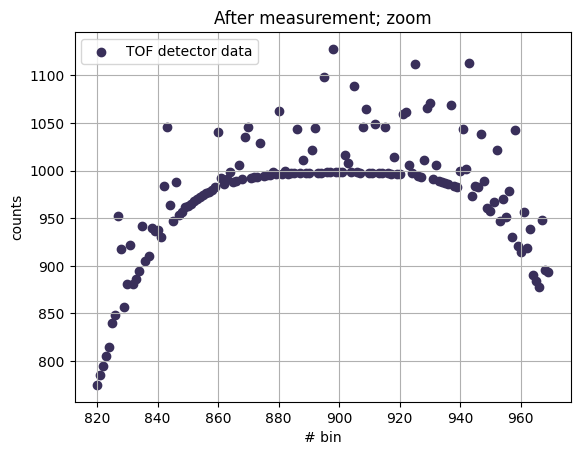

In [6]:
detector1.plot(title="After measurement", cut1=None, cut2=None)
detector1.plot(title="After measurement; zoom", cut1=820, cut2=970)

In [7]:
# analyze convoluted spectrum
t_convolution_offset = chopper_open_time_ms / 2.0
t_convolution_offset_err = (chopper1.t_open_ms - 0.0) * 0.6827 *0.5


rawTOF_poissonian_convoluted = RawTOFPointList(detector1.data, 
                         s=631, 
                         label = "Convoluted",
                         convolution_t=t_convolution_offset,
                         convolution_t_err=t_convolution_offset_err)

rebinnedTOF_poissonian_convoluted = RebinnedTOFPointList(rawTOF_poissonian_convoluted,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned convoluted")

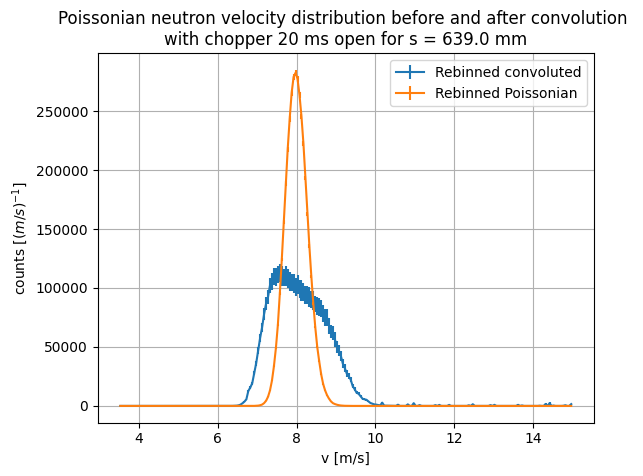

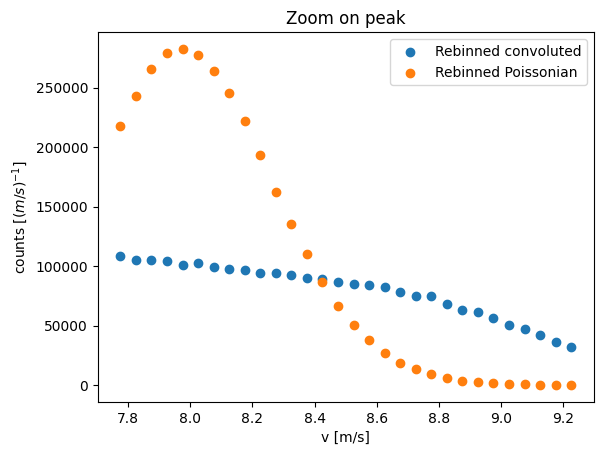

In [8]:

# plot spectra for debug
plt.errorbar(rebinnedTOF_poissonian_convoluted.v, 
             rebinnedTOF_poissonian_convoluted.N_v, 
             rebinnedTOF_poissonian_convoluted.N_v_err,
             label= rebinnedTOF_poissonian_convoluted.label)
plt.errorbar(rebinnedTOF_poissonian.v,
             rebinnedTOF_poissonian.N_v,
             rebinnedTOF_poissonian.N_v_err,
             label= rebinnedTOF_poissonian.label)
plt.xlabel("v [m/s]")
plt.ylabel(r"counts [$(m/s)^{-1}$]")
plt.legend()
plt.grid(True)
plt.title(f"Poissonian neutron velocity distribution before and after convolution \nwith chopper {chopper1.t_open_ms} ms open for s = {rebinnedTOF_poissonian.s} mm")
plt.show()

cut1 = 85
cut2 = 115
plt.scatter(rebinnedTOF_poissonian_convoluted.v[cut1:cut2], 
             rebinnedTOF_poissonian_convoluted.N_v[cut1:cut2], 
             label= rebinnedTOF_poissonian_convoluted.label)
plt.scatter(rebinnedTOF_poissonian.v[cut1:cut2],
             rebinnedTOF_poissonian.N_v[cut1:cut2],
             label= rebinnedTOF_poissonian.label)
plt.xlabel("v [m/s]")
plt.ylabel(r"counts [$(m/s)^{-1}$]")
plt.legend()
plt.title("Zoom on peak")
plt.show()

# NaN warner
for i in range(rebinnedTOF_poissonian.length):
    N_v = rebinnedTOF_poissonian[i].N_v
    if np.isnan(N_v):
        print(f"nan at index {i}")
        print(f"v = {rebinnedTOF_poissonian[i].v} m/s")
    elif np.isinf(N_v):
        print('+-inf')


Fit parameters: A=282187.89+-1029.80, mean=7.9853+-0.0012, sigma=0.28+-0.00
Fit parameters: A=114082.80+-2739.01, mean=7.9798+-0.0205, sigma=0.74+-0.02


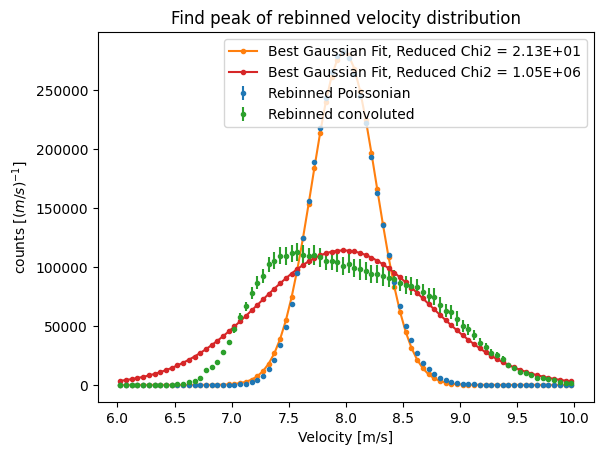

In [9]:
# analyze the pure spectrum and the spectrum after convolution by fitting a gauss to the peak
v_low, v_high = 6.0, 10.0
v_peak_poisson, v_peak_poisson_err = rebinnedTOF_poissonian.find_peak_velocity(gausstype='threepoints', 
                                                                         v_low=v_low, 
                                                                         v_high=v_high, 
                                                                         a0 = 250000.0, 
                                                                         mu0= 8.0, 
                                                                         sigma0=1.0, 
                                                                         do_plot=True, 
                                                                         do_print=True)
v_peak_convoluted, v_peak_convoluted_err = rebinnedTOF_poissonian_convoluted.find_peak_velocity(gausstype='threepoints', 
                                                                                          v_low=v_low, 
                                                                                          v_high=v_high, 
                                                                                          a0 = 250000.0, 
                                                                                          mu0= 8.0, 
                                                                                          sigma0=1.0, 
                                                                                          do_plot=True, 
                                                                                          do_print=True)

In [10]:
v_mean_poisson, v_mean_poisson_err = rebinnedTOF_poissonian.find_mean_velocity(do_print=True)
#v_mean_convoluted1, v_mean_convoluted_err1 = rebinnedTOF_poissonian_convoluted.find_mean_velocity(do_print=True, do_newcode=False)
v_mean_convoluted2, v_mean_convoluted_err2 = rebinnedTOF_poissonian_convoluted.find_mean_velocity(do_print=True, do_newcode=True)

v_rms_poisson, v_rms_poisson_err = rebinnedTOF_poissonian.find_rms_velocity(do_print=True)
v_rms_convoluted, v_rms_convoluted_err = rebinnedTOF_poissonian_convoluted.find_rms_velocity(do_print=True)

Mean velocity for Rebinned Poissonian = 7.9980 +- 0.0006 m/s
Mean velocity for Rebinned convoluted = 8.0756 +- 0.1298 m/s
Mean velocity for Rebinned convoluted = 8.0756 +- 0.0066 m/s
Root mean squared velocity for Rebinned Poissonian = 8.0030 +- 0.0013 m/s
Root mean squared velocity for Rebinned convoluted = 8.1099 +- 0.0137 m/s
